# Load votes and compute a spectral start

A block model only reaches a local optimum, and where it starts largely decides where it
ends. This notebook loads a vote matrix from a CSV file and computes the arrangement of
**regularised spectral co-clustering**, the start that `SpectralStart` hands to the block
models of `civiqhub_selene.blocks`:

1. load the votes and look at them;
2. compute the spectral embedding and read its spectrum;
3. see the "star" of the embedding and its projection onto the sphere;
4. find groups and blocks by k-means, before any model;
5. compare the two encodings of the votes, and the effect of the regulariser.

The data are **synthetic**: they were drawn by `make_votes` from a planted truth, which
we use to check what the method finds (`data/make_data.py` says how).

Requirements: `pip install "civiqhub-selene[viz]"`, run from the `examples/` folder.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from loading import planted_blocks, planted_groups, read_votes

from civiqhub_selene import viz
from civiqhub_selene.blocks import Partition, SpectralStart
from civiqhub_selene.blocks.spectral import spectral_embedding

plt.rcParams["figure.dpi"] = 90

## 1. Load the votes

The file has one row per *shown* cell: `voter,item,score`. An empty score is a cell
shown without a vote; a pair (voter, item) without a row was not shown. These are the
three states of a cell in a `VoteMatrix`: an empty cell is never read as a zero nor as a
neutral answer.

In [2]:
votes = read_votes("data/consultation.votes.csv")
print(votes)

VoteMatrix(240 voters x 24 items, 2746 votes, 5 levels)
73.2% of the 5760 cells shown, 65.1% of the shown cells voted


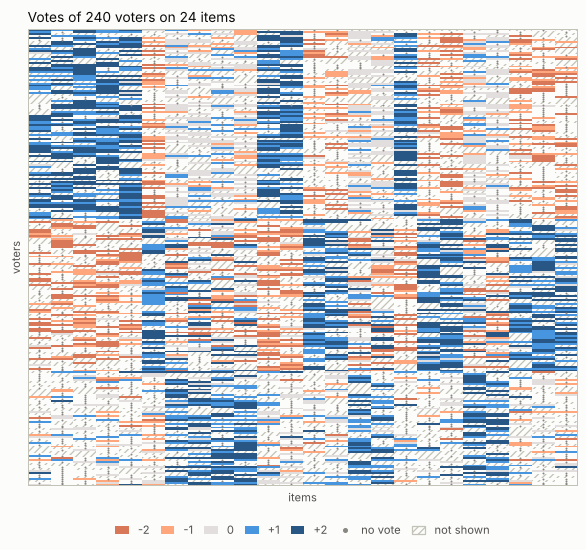

In [3]:
viz.plot_vote_matrix(votes)
plt.show()

In the order of the file, no structure is visible: votes of every colour everywhere,
abstentions (dots) and cells that were not shown (hatching), more or fewer of them from
one voter to the next.

## 2. The spectral embedding

Each side of the matrix is written as a nonnegative matrix $A$ and normalised by its
**regularised degrees** (Rohe, Qin and Yu 2016, equation 1):

$$L = (O + \tau_r I)^{-1/2}\, A\, (P + \tau_c I)^{-1/2}$$

where $O$ and $P$ hold the sums of the rows and of the columns of $A$, and each
regulariser $\tau$ is the average degree of its side (Qin and Rohe 2013). With the
default encoding `"states"`, $A$ has one row per voter and one column per pair
(item, state): $A A^\top$ counts the items on which two voters gave the same answer, and
the degree of a voter is its number of shown cells. The leading singular vectors of $L$
place each voter, and likewise each item, in a space of a few dimensions.

SpectralEmbedding(240 voters in 3 dimensions x 24 items in 3 dimensions, encoding 'states')
leading singular values of the voters: 0.527, 0.364, 0.251, 0.182, 0.181
leading singular values of the items: 0.537, 0.385, 0.341, 0.262, 0.261


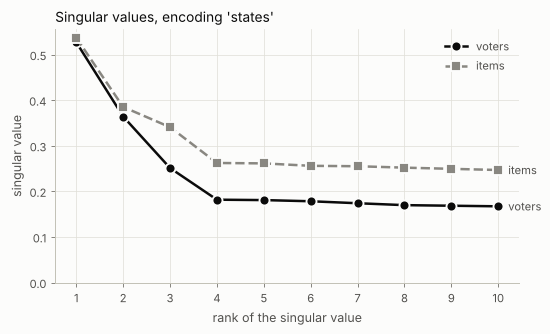

In [4]:
embedding = spectral_embedding(votes, n_voter_components=3, n_item_components=3)
print(embedding)
viz.plot_spectrum(embedding)
plt.show()

On both sides, the singular values drop after the third: a hint that there are three
groups and three blocks. It is a hint, not a choice: the integrated likelihood chooses
the shape (notebook 02).

## 3. The star and its projection

Under a degree-corrected block model, the rows of one group share a *direction* and
differ in *length* with the participation of each voter (Qin and Rohe 2013, figure 1).
Projected onto the unit sphere, each group gathers on one point. Colours are the planted
groups.

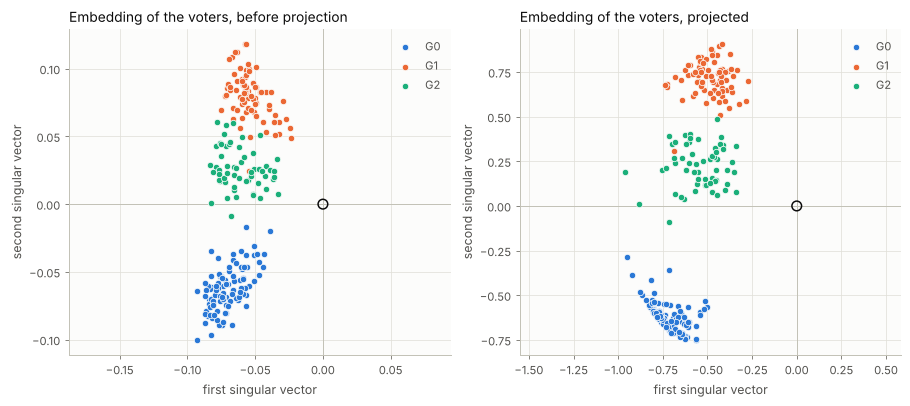

In [5]:
planted = planted_groups(votes, "data/consultation.voters.csv")
planted_items = planted_blocks(votes, "data/consultation.items.csv")

figure, (left, right) = plt.subplots(1, 2, figsize=(10, 4.4), layout="constrained")
viz.plot_embedding(embedding, planted.labels, ax=left)
viz.plot_embedding(embedding, planted.labels, project=True, ax=right)
plt.show()

## 4. Groups and blocks before any model

k-means on the projected rows gives a group to each voter and a block to each item. The
generator `rng` only seeds k-means++: the decomposition itself has no randomness.

In [6]:
groups, blocks = embedding.labels(3, 3, np.random.default_rng(0))
found_groups = Partition.from_voter_labels(votes.voters, groups)
found_blocks = Partition.from_item_labels(votes.items, blocks)
print(f"voters arranged as planted: {found_groups.agreement_with(planted):.1%}")
print(f"items arranged as planted:  {found_blocks.agreement_with(planted_items):.1%}")

voters arranged as planted: 98.8%
items arranged as planted:  100.0%


## 5. Two encodings of the votes

The encoding `"scores"` decomposes one matrix of centred scores, as DI-SIM does for a
graph. It is cheaper, but it reads a neutral vote, an abstention and a cell that was not
shown as the same 0, and it only sees mean opinions. On the third block of this
collective, groups 0 and 1 have the **same mean opinion**: group 0 agrees on a neutral
score, group 1 is split between the two ends of the scale. Read on that block alone,
only the encoding `"states"` tells them apart; `"scores"` is no better than chance (50%).

In [7]:
third_block = votes[planted[0] | planted[1], planted_items[2]]
truth = Partition.from_voter_labels(
    third_block.voters, [0 if voter in planted[0] else 1 for voter in third_block.voters]
)
for encoding in ("states", "scores"):
    embedding_of_block = spectral_embedding(
        third_block, n_voter_components=2, n_item_components=1, encoding=encoding
    )
    groups, _ = embedding_of_block.labels(2, 1, np.random.default_rng(0))
    found = Partition.from_voter_labels(third_block.voters, groups)
    print(f"{encoding:<7} voters of groups 0 and 1 told apart: {found.agreement_with(truth):.1%}")

states  voters of groups 0 and 1 told apart: 87.8%
scores  voters of groups 0 and 1 told apart: 51.1%


On the whole matrix, the two other blocks already separate the groups, and both
encodings do well. `regularization` multiplies the average degree used as $\tau$ (0 is
unregularised spectral clustering); `leverage_threshold` is the $\gamma$ of thresholded
spectral clustering (t-RSC), where k-means only reads the voters whose row is long enough
and the others take the nearest centroid. On this collective they change little: they
matter when participation is very uneven, with many voters who cast a handful of votes.

In [8]:
print(f"{'encoding':<10}{'regularization':>16}{'leverage':>10}{'voters':>9}{'items':>8}")
for encoding in ("states", "scores"):
    for regularization in (0.0, 1.0):
        for leverage in (0.0, 1.0):
            start = SpectralStart(
                encoding=encoding, regularization=regularization, leverage_threshold=leverage
            )
            groups, blocks = start.arrangement(votes, (3, 3), np.random.default_rng(0))
            voters = Partition.from_voter_labels(votes.voters, groups).agreement_with(planted)
            items = Partition.from_item_labels(votes.items, blocks).agreement_with(planted_items)
            print(f"{encoding:<10}{regularization:>16}{leverage:>10}{voters:>9.1%}{items:>8.1%}")

encoding    regularization  leverage   voters   items
states                 0.0       0.0    99.6%  100.0%
states                 0.0       1.0    99.6%  100.0%
states                 1.0       0.0    98.8%  100.0%
states                 1.0       1.0    98.8%  100.0%
scores                 0.0       0.0    97.9%  100.0%
scores                 0.0       1.0    97.9%  100.0%
scores                 1.0       0.0    97.5%  100.0%
scores                 1.0       1.0    97.5%  100.0%


## 6. Hand the start to a model

`SpectralStart()` is a setting of a block model, like its response model. It enters the
provenance of the result:

```python
from civiqhub_selene.blocks import LatentBlockModel, SpectralStart

model = LatentBlockModel(n_groups=3, n_blocks=3, initialization=SpectralStart())
result = model.estimate(votes, seed=0)
```

The next notebooks run the full inference: `02_olbm.ipynb` with one group per voter,
`03_mm_olbm.ipynb` with mixed memberships.

**References.** Qin and Rohe (2013), *Regularized spectral clustering under the
degree-corrected stochastic blockmodel*, NeurIPS 26. Rohe, Qin and Yu (2016),
*Co-clustering directed graphs to discover asymmetries and directional communities*,
PNAS 113(45).